# BƯỚC 5.3: LỌC CỘNG TÁC: MATRIX FACTORIZATION (ALS) TRÊN DỮ LIỆU MÔ PHỎNG
---
Dữ liệu tương tác do **notebook 01** sinh ra và đã được xem kỹ ở **notebook 02**. Notebook này:

1. **Nạp** dữ liệu mô phỏng từ `data/simulated/`;
2. **Thiết lập đánh giá**: chia theo thời gian, các chỉ số Recall / NDCG (theo log) và **Oracle-P@10** (theo sở thích thật);
3. So sánh **6 mô hình**: Phổ biến, ItemKNN, SVD, **ALS**, CBF, Hybrid;
4. Chọn tham số trên validation, đo trên test;
5. **Phân tích độ nhạy** khi tỷ trọng nội dung / phần ẩn trong sở thích thay đổi;
6. **Lưu** tham số ALS và trọng số Hybrid đã chọn vào `config.json` (notebook 07 và ứng dụng đọc lại).

## 1. Nạp dữ liệu mô phỏng

In [1]:
import os, sys, json, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize as l2_normalize

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)
ROOT = os.path.abspath(os.path.join('..', '..'))
SIM_DIR = os.path.join(ROOT, 'data', 'simulated')
if not os.path.exists(os.path.join(SIM_DIR, 'z_content.npy')):
    raise FileNotFoundError("Chưa có dữ liệu mô phỏng đầy đủ trong data/simulated/: hãy chạy notebook 01 trước.")

config = json.load(open(os.path.join(SIM_DIR, 'config.json'), encoding='utf-8'))
SEED, N_USERS, N_DAYS = config['seed'], config['n_users'], config['n_days']
SNAPSHOT = pd.Timestamp(config['snapshot'])

# Tin: thứ tự = thứ tự cột của ma trận U (jobs_hidden.csv), thông tin nội dung lấy từ jobs_clean.csv
job_meta = pd.read_csv(os.path.join(SIM_DIR, 'jobs_hidden.csv'))
clean = pd.read_csv(os.path.join(ROOT, 'data', 'notebook', 'content_base', 'jobs_clean.csv')).set_index('job_id')
missing = set(job_meta['job_id']) - set(clean.index)
if missing:
    raise ValueError(f"{len(missing):,} tin của bộ mô phỏng không còn trong jobs_clean.csv: hãy chạy lại notebook 01.")
jobs = pd.concat([clean.loc[job_meta['job_id']].reset_index(),
                  job_meta[['domain', 'open_day', 'close_day', 'company_type']].reset_index(drop=True)], axis=1)
jobs['skills'] = jobs['required_skills'].fillna('').map(lambda s: [x.strip() for x in s.split(',') if x.strip()])
job_idx = {j: i for i, j in enumerate(jobs['job_id'])}
open_d, close_d = jobs['open_day'].values, jobs['close_day'].values

users = pd.read_csv(os.path.join(SIM_DIR, 'users.csv'))
users['skills'] = users['skills'].fillna('').map(lambda s: [x.strip() for x in s.split(',') if x.strip()])
job_exp = jobs['experience_min'].fillna(0).values
ucity, jcity = users['city'].to_numpy(dtype=object)[:, None], jobs['city'].to_numpy(dtype=object)[None, :]

# Sự kiện mà CF được học (α = 0,5)
events_05 = pd.read_csv(os.path.join(SIM_DIR, 'interactions_alpha0.5.csv'))
events_05['job_idx'] = events_05['job_id'].map(job_idx)
events_05 = events_05[['user_id', 'job_idx', 'day', 'position', 'source', 'event', 'weight']]

# Sở thích thật U_α = α·z(Nội dung) + (1-α)·z(Ẩn): CHỈ dùng để chấm điểm (Oracle-P@10), mô hình không được đọc
Z_CONTENT = np.load(os.path.join(SIM_DIR, 'z_content.npy'))
Z_HIDDEN = np.load(os.path.join(SIM_DIR, 'z_hidden.npy'))
def true_utility(alpha):
    return alpha * Z_CONTENT + (1 - alpha) * Z_HIDDEN

# Lượt hiển thị + số ngẫu nhiên của phễu: để sinh lại sự kiện ở mức α khác (mục 5), giống hệt notebook 01
impressions = pd.read_csv(os.path.join(SIM_DIR, 'impressions.csv'))
impressions['job_idx'] = impressions['job_id'].map(job_idx)
draws = np.load(os.path.join(SIM_DIR, 'impression_draws.npy'))
impressions['r_examine'], impressions['r_click'], impressions['r_save'], impressions['r_apply'] = draws.T
EVENT_WEIGHT = config['event_weight']
FUNNEL = {k: tuple(v) for k, v in config['funnel'].items()}
sigmoid = lambda x: 1 / (1 + np.exp(-x))

def simulate_events(alpha):
    """Phễu hành vi của notebook 01 áp lên cùng các lượt hiển thị ➔ bảng sự kiện ở mức α."""
    Ua = true_utility(alpha)[impressions['user_id'].values, impressions['job_idx'].values]
    examined = impressions['r_examine'].values < 1 / np.log2(impressions['position'].values + 2)
    p = {e: sigmoid(a * Ua + b) for e, (a, b) in FUNNEL.items()}
    click = examined & (impressions['r_click'].values < p['click'])
    save = click & (impressions['r_save'].values < p['save'])
    apply_ = click & (impressions['r_apply'].values < p['apply'])
    ev = impressions.loc[click, ['user_id', 'job_idx', 'day', 'position', 'source']].copy()
    ev['event'] = np.where(apply_[click], 'apply', np.where(save[click], 'save', 'click'))
    ev['weight'] = ev['event'].map(EVENT_WEIGHT)
    return ev.reset_index(drop=True)

# Tự kiểm tra: sinh lại ở α = 0,5 phải ra đúng file đã lưu
_re = simulate_events(0.5)
assert len(_re) == len(events_05) and (_re['event'].values == events_05['event'].values).all(), "Dữ liệu mô phỏng không khớp: chạy lại notebook 01."
print(f"Dữ liệu mô phỏng ngày {SNAPSHOT.date()}: {N_USERS:,} người dùng × {len(jobs):,} tin, {len(events_05):,} sự kiện "
      f"({', '.join(f'{k}: {v:,}' for k, v in events_05['event'].value_counts().items())}) | sinh lại ở α = 0,5: khớp")

Dữ liệu mô phỏng ngày 2026-11-16: 3,000 người dùng × 3,675 tin, 27,931 sự kiện (click: 19,272, save: 5,674, apply: 2,985) | sinh lại ở α = 0,5: khớp


## 2. Thiết lập đánh giá

- **Chia theo thời gian**: train = sự kiện trước ngày 45, test = 10 ngày cuối. Không chia ngẫu nhiên vì như vậy mô hình được "nhìn thấy tương lai".
- **Validation**: để chọn tham số mà không "nhìn" tập test, dùng thêm một lần chia sớm hơn: train = trước ngày 38, validation = ngày 38-44.
- **Người dùng được đánh giá**: có ít nhất 1 sự kiện ở train và 1 sự kiện ở test.
- **Ứng viên**: các tin còn mở trong giai đoạn test, bỏ các tin người dùng đã tương tác ở train.
- **Chỉ số**:
  - **Recall@10, NDCG@10** so với sự kiện test (lợi ích: bấm = 1, lưu = 2, ứng tuyển = 3), giống cách đánh giá trên log thật;
  - **Oracle-P@10**: tỷ lệ tin gợi ý nằm trong **top-10 theo mức độ thích thật** $U(u, j)$. Chỉ đo được nhờ mô phỏng, và không bị giới hạn bởi việc người dùng chỉ thấy một phần kho;
  - **Recall@10 trên tin mới** (*cold-start*): chỉ tính các sự kiện test vào tin **chưa có tương tác nào ở train**;
  - **Độ phủ**: phần trăm tin ứng viên xuất hiện trong ít nhất một danh sách gợi ý.

In [2]:
VAL_START, TEST_START, K = 38, 45, 10
n_items = len(jobs)

def build_split(ev, start=TEST_START, end=N_DAYS + 1):
    """Train = sự kiện trước ngày `start`; đánh giá = sự kiện trong [start, end)."""
    tr, te = ev[ev.day < start], ev[(ev.day >= start) & (ev.day < end)]
    R = (tr.groupby(['user_id', 'job_idx'])['weight'].max().reset_index())
    R = sp.csr_matrix((R['weight'].values.astype(np.float32), (R['user_id'].values, R['job_idx'].values)), shape=(N_USERS, n_items))
    gains = te.assign(g=te['event'].map({'click': 1, 'save': 2, 'apply': 3})).groupby(['user_id', 'job_idx'])['g'].max()
    eval_users = np.array(sorted(set(te.user_id) & set(tr.user_id)))
    cand = (close_d >= start) & (open_d < end)                         # tin còn mở trong giai đoạn đánh giá
    warm_items = np.asarray((R > 0).sum(0)).ravel() > 0
    return {'R': R, 'gains': gains, 'eval_users': eval_users, 'cand': cand, 'warm_items': warm_items}

def evaluate(scores, split, U_true):
    """scores: (len(eval_users), n_items). Trả về các chỉ số trung bình."""
    R, cand, warm = split['R'], split['cand'], split['warm_items']
    rec, ndcg, orac, cold_hit, cold_tot, covered = [], [], [], 0, 0, set()
    disc = 1 / np.log2(np.arange(2, K + 2))
    for row, u in enumerate(split['eval_users']):
        mask = cand.copy(); mask[R[u].indices] = False
        s = np.where(mask, scores[row], -np.inf)
        top = np.argpartition(-s, K)[:K]; top = top[np.argsort(-s[top])]
        covered.update(top.tolist())
        g = split['gains'].loc[u]
        pos = {int(j): v for j, v in g.items() if mask[int(j)]}
        if pos:
            hit = [pos.get(int(j), 0) for j in top]
            rec.append(sum(h > 0 for h in hit) / min(K, len(pos)))
            ideal = sorted(pos.values(), reverse=True)[:K]
            ndcg.append(np.sum((2 ** np.array(hit) - 1) * disc) / np.sum((2 ** np.array(ideal) - 1) * disc[:len(ideal)]))
            cold = [j for j in pos if not warm[j]]
            cold_tot += len(cold); cold_hit += len(set(cold) & set(top.tolist()))
        ut = np.where(mask, U_true[u], -np.inf)
        orac.append(len(set(top.tolist()) & set(np.argpartition(-ut, K)[:K].tolist())) / K)
    return {'Recall@10': np.mean(rec), 'NDCG@10': np.mean(ndcg), 'Oracle-P@10': np.mean(orac),
            'Recall@10 tin mới': cold_hit / cold_tot if cold_tot else np.nan, 'Độ phủ': len(covered) / cand.sum()}

split_05 = build_split(events_05)
val_05 = build_split(events_05, VAL_START, TEST_START)
print(f"Train: {split_05['R'].nnz:,} cặp user-job | người dùng đánh giá: {len(split_05['eval_users']):,} | "
      f"tin ứng viên: {split_05['cand'].sum():,}, trong đó {(~split_05['warm_items'] & split_05['cand']).sum():,} tin chưa có tương tác ở train")

Train: 21,337 cặp user-job | người dùng đánh giá: 1,369 | tin ứng viên: 2,470, trong đó 518 tin chưa có tương tác ở train


## 3. Các mô hình

| Mô hình | Loại | Ý tưởng |
|---|---|---|
| **Phổ biến** | đối chứng | tin được tương tác nhiều nhất ở train |
| **ItemKNN** | CF theo láng giềng | tin giống các tin bạn đã tương tác (cosine trên cột ma trận tương tác) |
| **SVD** | MF *sai cách* | `TruncatedSVD` coi mọi ô trống là 0 = "không thích" |
| **ALS** | **MF cho phản hồi ngầm** | ô trống = "chưa biết", độ tin cậy $c_{uj} = 1 + a \cdot w_{uj}$ (bấm 1, lưu 3, ứng tuyển 5) |
| **CBF** | nội dung | bản rút gọn của notebook 05: TF-IDF (tiêu đề + kỹ năng) so với kỹ năng hồ sơ, cộng điểm kinh nghiệm và thành phố |
| **Hybrid** | kết hợp | $w \cdot z(\text{CBF}) + (1 - w) \cdot z(\text{ALS})$, chuẩn hóa z-score theo từng người dùng. Tin **chưa có tương tác** (ALS không biết) chỉ dùng $z(\text{CBF})$, cùng quy tắc "thiếu dữ liệu thì bỏ thành phần" như notebook 05 |



In [ ]:
def als_implicit(R, k=16, reg=1.0, alpha_conf=1.0, iters=12, seed=0):
    rng_ = np.random.default_rng(seed)
    X = rng_.normal(0, 0.01, (R.shape[0], k));
    Y = rng_.normal(0, 0.01, (R.shape[1], k))
    Rt, I = R.T.tocsr(), reg * np.eye(k)

    def update(A, B, M):
        BtB = B.T @ B
        for r in range(M.shape[0]):
            s, e = M.indptr[r], M.indptr[r + 1]
            if s == e:
                A[r] = 0; continue
            idx, c = M.indices[s:e], 1 + alpha_conf * M.data[s:e]
            Bi = B[idx]
            A[r] = np.linalg.solve(BtB + (Bi.T * (c - 1)) @ Bi + I, Bi.T @ c)

    for _ in range(iters):
        update(X, Y, R); update(Y, X, Rt)
    return X, Y

def scores_popular(split):
    pop = np.asarray((split['R'] > 0).sum(0)).ravel().astype(float)
    return np.tile(pop, (len(split['eval_users']), 1))

def scores_itemknn(split):
    B = (split['R'] > 0).astype(np.float32)
    Bn = l2_normalize(B.T.tocsr(), axis=1)                     # vector cột của từng tin
    S = (Bn @ Bn.T).toarray(); np.fill_diagonal(S, 0)
    return np.asarray(split['R'][split['eval_users']] @ S)

def scores_svd(split, k=32):
    svd = TruncatedSVD(n_components=k, random_state=SEED)
    Xu = svd.fit_transform((split['R'] > 0).astype(np.float32))
    return Xu[split['eval_users']] @ svd.components_

ALS_PARAMS = {'k': 16, 'reg': 1.0, 'alpha_conf': 1.0}   # giá trị mặc định; được chọn lại trên validation ở mục 5
W_CBF = 0.5

def scores_als(split, **kw):
    X, Y = als_implicit(split['R'], **{**ALS_PARAMS, **kw})
    return X[split['eval_users']] @ Y.T

# CBF rút gọn (notebook 05 không được import theo nguyên tắc notebook-first)
tfidf = TfidfVectorizer(token_pattern=r"(?u)[\w+#.]+", ngram_range=(1, 2), min_df=2)
JOB_TEXT = tfidf.fit_transform(jobs['title'].fillna('') + ' ' + jobs['skills'].map(lambda s: ' '.join(s * 2)))
USER_TEXT = tfidf.transform(users['skills'].map(' '.join))
CBF_ALL = ((USER_TEXT @ JOB_TEXT.T).toarray()
           + 0.2 * np.clip(1 - np.maximum(job_exp[None, :] - users['exp'].values[:, None], 0) / 3, 0, 1)
           + 0.1 * np.where((ucity == 'Tất cả') | (ucity == jcity), 1.0, 0.0))

def scores_cbf(split):
    return CBF_ALL[split['eval_users']]

def zrow(S, mask):
    S = np.where(mask, S, np.nan)
    return np.nan_to_num((S - np.nanmean(S, 1, keepdims=True)) / (np.nanstd(S, 1, keepdims=True) + 1e-9))

def scores_hybrid(split, als_scores, w_cbf=None):
    w = W_CBF if w_cbf is None else w_cbf
    zc, za = zrow(scores_cbf(split), split['cand']), zrow(als_scores, split['cand'])
    return np.where(split['warm_items'][None, :], w * zc + (1 - w) * za, zc)   # tin mới: chỉ dùng CBF

t0 = time.time(); _ = als_implicit(split_05['R'], iters=1); print(f"Một vòng ALS: {time.time() - t0:.1f}s")

Một vòng ALS: 0.1s


## 4. Kết quả ở $\alpha = 0{,}5$ (nội dung và phần ẩn quan trọng ngang nhau)

### 4.1. Chọn tham số trên tập validation
Chọn tham số của ALS (số chiều ẩn $k$, hệ số phạt $\lambda$, hệ số tin cậy $a$) và trọng số $w$ của Hybrid bằng **NDCG@10 trên validation** (train trước ngày 38, đánh giá ngày 38-44). Tập test **không** được dùng ở bước này.

In [4]:
U_05 = true_utility(0.5)
grid = []
for k in [8, 16, 32]:
    for reg in [0.1, 1.0, 10.0]:
        for ac in [1.0, 5.0, 20.0]:
            r = evaluate(scores_als(val_05, k=k, reg=reg, alpha_conf=ac), val_05, U_05)
            grid.append({'k': k, 'λ': reg, 'a': ac, 'NDCG@10 (val)': r['NDCG@10'], 'Recall@10 (val)': r['Recall@10']})
grid = pd.DataFrame(grid).sort_values('NDCG@10 (val)', ascending=False)
display(grid.head(8).round(4))
best = grid.iloc[0]
ALS_PARAMS = {'k': int(best['k']), 'reg': float(best['λ']), 'alpha_conf': float(best['a'])}

als_val = scores_als(val_05)
w_grid = pd.Series({w: evaluate(scores_hybrid(val_05, als_val, w), val_05, U_05)['NDCG@10'] for w in [0.3, 0.5, 0.7, 0.8, 0.9]},
                   name='NDCG@10 (val)').rename_axis('w (CBF)')
display(w_grid.round(4).to_frame())
W_CBF = float(w_grid.idxmax())
print("Chọn:", ALS_PARAMS, "| w_CBF =", W_CBF)

,k,λ,a,NDCG@10 (val),Recall@10 (val)
24,32,10.0,1.0,0.0539,0.0889
25,32,10.0,5.0,0.0537,0.0899
22,32,1.0,5.0,0.0532,0.0908
19,32,0.1,5.0,0.0532,0.0908
18,32,0.1,1.0,0.0532,0.0918
10,16,0.1,5.0,0.0522,0.0935
13,16,1.0,5.0,0.0522,0.0933
21,32,1.0,1.0,0.0520,0.0887


,NDCG@10 (val)
w (CBF),
0.3,0.0625
0.5,0.0713
0.7,0.0814
0.8,0.0811
0.9,0.0650


Chọn: {'k': 32, 'reg': 10.0, 'alpha_conf': 1.0} | w_CBF = 0.7


### 4.2. Kết quả trên tập test

In [5]:
def run_all(split, U_true):
    t0 = time.time()
    als = scores_als(split)
    models = {
        'Phổ biến': scores_popular(split), 'ItemKNN': scores_itemknn(split), 'SVD (sai cách)': scores_svd(split, k=ALS_PARAMS['k']),
        'ALS (MF phản hồi ngầm)': als, 'CBF': scores_cbf(split), 'Hybrid CBF + ALS': scores_hybrid(split, als),
    }
    out = pd.DataFrame({name: evaluate(S, split, U_true) for name, S in models.items()}).T
    print(f"  ({time.time() - t0:.0f}s)")
    return out

res_05 = run_all(split_05, U_05)
display(res_05.round(3))

  (5s)


,Recall@10,NDCG@10,Oracle-P@10,Recall@10 tin mới,Độ phủ
Phổ biến,0.008,0.005,0.049,0.000,0.005
ItemKNN,0.071,0.040,0.117,0.000,0.714
SVD (sai cách),0.084,0.051,0.190,0.000,0.221
ALS (MF phản hồi ngầm),0.094,0.060,0.224,0.000,0.198
CBF,0.081,0.052,0.104,0.096,0.707
Hybrid CBF + ALS,0.123,0.082,0.247,0.111,0.588


## 5. Phân tích độ nhạy: thay đổi $\alpha$
- $\alpha$ nhỏ: sở thích chủ yếu là **phần ẩn** (loại công ty, thương hiệu): lợi thế thuộc về CF.
- $\alpha$ lớn: sở thích chủ yếu là **khớp nội dung**: lợi thế thuộc về CBF.

Câu hỏi: ở vùng nào CF thắng CBF, và Hybrid có an toàn ở mọi vùng không?

Tham số của ALS và trọng số Hybrid được **giữ nguyên** như đã chọn ở $\alpha = 0{,}5$ (không chọn lại cho từng $\alpha$), vì trên thực tế ta không biết $\alpha$ thật.

In [6]:
ALPHAS = [0.2, 0.35, 0.5, 0.65, 0.8]
sweep = {}
for a in ALPHAS:
    print(f"α = {a}:", end='')
    ev = simulate_events(a)
    sweep[a] = run_all(build_split(ev), true_utility(a))
sens = pd.concat(sweep, names=['α', 'Mô hình'])
print("\nOracle-P@10 (so với sở thích THẬT, chỉ đo được nhờ mô phỏng):")
display(sens['Oracle-P@10'].unstack().round(3))
print("NDCG@10 (so với sự kiện test, giống đánh giá trên log thật):")
display(sens['NDCG@10'].unstack().round(3))

α = 0.2:  (4s)
α = 0.35:  (4s)
α = 0.5:  (5s)
α = 0.65:  (5s)
α = 0.8:  (5s)

Oracle-P@10 (so với sở thích THẬT, chỉ đo được nhờ mô phỏng):


Mô hình,Phổ biến,ItemKNN,SVD (sai cách),ALS (MF phản hồi ngầm),CBF,Hybrid CBF + ALS
α,,,,,,
0.20,0.188,0.047,0.143,0.174,0.027,0.119
0.35,0.109,0.080,0.182,0.225,0.059,0.191
0.50,0.049,0.117,0.190,0.224,0.104,0.247
0.65,0.028,0.150,0.183,0.209,0.157,0.307
0.80,0.014,0.169,0.178,0.201,0.209,0.370


NDCG@10 (so với sự kiện test, giống đánh giá trên log thật):


Mô hình,Phổ biến,ItemKNN,SVD (sai cách),ALS (MF phản hồi ngầm),CBF,Hybrid CBF + ALS
α,,,,,,
0.20,0.011,0.036,0.068,0.078,0.025,0.073
0.35,0.008,0.034,0.062,0.070,0.037,0.077
0.50,0.005,0.040,0.051,0.060,0.052,0.082
0.65,0.003,0.053,0.053,0.058,0.062,0.091
0.80,0.002,0.055,0.055,0.058,0.065,0.100


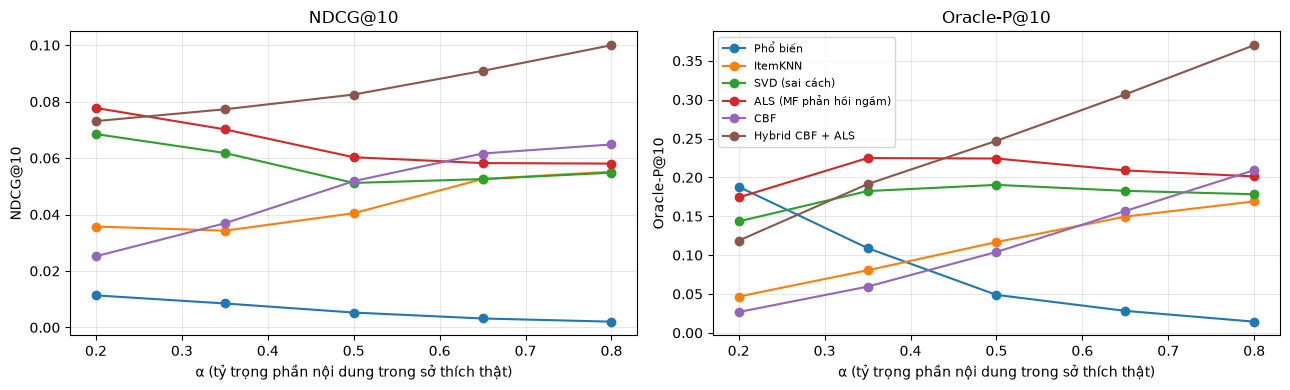

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ['NDCG@10', 'Oracle-P@10']):
    for name in ['Phổ biến', 'ItemKNN', 'SVD (sai cách)', 'ALS (MF phản hồi ngầm)', 'CBF', 'Hybrid CBF + ALS']:
        ax.plot(ALPHAS, sens[metric].unstack().loc[ALPHAS, name], marker='o', label=name)
    ax.set(title=metric, xlabel='α (tỷ trọng phần nội dung trong sở thích thật)', ylabel=metric)
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

càng cao thì sở thích càng dựa vào phần nội dung

## 6. Lưu tham số đã chọn
Tham số ALS ($k$, $\lambda$, $a$) và trọng số Hybrid chọn trên validation ở mục 4.1 được ghi vào `data/simulated/config.json`: notebook 07 dùng lại, ứng dụng Streamlit đọc tham số ALS từ đây (`src/recommender/collaborative.py`).

In [8]:
cfg_path = os.path.join(SIM_DIR, 'config.json')
cfg = json.load(open(cfg_path, encoding='utf-8'))
cfg.update({'als_params': ALS_PARAMS, 'w_cbf': W_CBF, 'val_start_day': VAL_START, 'test_start_day': TEST_START})
with open(cfg_path, 'w', encoding='utf-8') as f:
    json.dump(cfg, f, ensure_ascii=False, indent=2)
print("Đã ghi vào config.json:", {'als_params': ALS_PARAMS, 'w_cbf': W_CBF})

Đã ghi vào config.json: {'als_params': {'k': 32, 'reg': 10.0, 'alpha_conf': 1.0}, 'w_cbf': 0.7}
